# Tome 15, Chapter 2: How to read a paper (Python companion)

A third pass is done with pencil, paper and a computer. Here we test, number by number, every step of the two proofs of Dubroff, Fox and Xu read in the chapter: the Berry–Esseen bound for signed sums (Proposition 2.2), the window count, the reduction of the second proof to a boundary count (Proposition 2.4), Harper's bound (Remark 2.5) on all small cases, and the tempting shortcut that the chapter rejects. The computer-science application is the **fast Fourier transform**, which computes the whole distribution of $X=\sum\pm a_i$ and Elkies's integral in one stroke. Exercises first, solutions at the end. Requires `numpy`.

In [1]:
import math, itertools
import numpy as np
def cg(n):
    u = [0, 1]
    for m in range(1, n):
        r = round(math.sqrt(2 * m))
        u.append(2 * u[m] - u[m - r])
    return sorted(u[n] - u[n - i] for i in range(1, n + 1))
def signed_values(A):
    v = np.array([0])
    for a in A:
        v = np.concatenate([v - a, v + a])
    return np.sort(v)
print(cg(6), signed_values([1, 2, 4])[:8])

[11, 17, 20, 22, 23, 24] [-7 -5 -3 -1  1  3  5  7]


## Exercises

**P2.1 (★) Testing the Berry–Esseen bound.** For the Conway–Guy sets $A_n$, $n=8,\dots,20$, and for sets of $n$ random integers in $[1,1000]$, compute $D=\sup_x|F(x)-\Phi(x)|$ exactly (the supremum is attained at a jump of $F$, on one side or the other) and compare it with $6.3\lambda$, where $\lambda=\max a_i/\sigma$. How wasteful is the constant $6.3$?

**P2.2 (★★) The window count.** For $A_{20}$, plot $2^nP(|X|\le\alpha\sigma)/(\alpha\sigma)$ against $\alpha$. The proof of Theorem 2.3 says that this is at least about $\sqrt{2/\pi}\,2^n/\sigma$ for small $\alpha$ and at most about $1$. Check both, and read off from the picture why a set with $\sigma$ much smaller than $\sqrt{2/\pi}\,2^n$ cannot exist.

**P2.3 (★★) Down-sets and their boundaries.** Enumerate all down-sets of subsets of $[n]$ for $n\le5$ (there are $2,3,6,20,168,7581$ of them for $n=0,\dots,5$, the Dedekind numbers), and among those containing $\emptyset$ but not $[n]$ find the minimum size of the outer vertex boundary: this tests the shortcut of Section 2.5. Then restrict to down-sets with exactly $2^{n-1}$ members and compare the minimum with $\binom n{\lfloor n/2\rfloor}$ (Harper's theorem, Remark 2.5). How many down-sets attain it?

**P2.4 (★★) The reduction, run on real data.** For a dissociated set $a$, build the family $\mathcal F=\{S: a\cdot\eta_S<0\}$, its boundary, and the numbers $a\cdot\eta_B$ for $B\in\partial\mathcal F$. Check, for the Conway–Guy sets up to $n=14$, that these numbers are distinct integers in $(0,a_n)$, and compare $|\partial\mathcal F|$ with $\binom n{\lfloor n/2\rfloor}$ and with $a_n$. How much room is there?

**P2.5 (★★★) CS application: the FFT.** The distribution of $X=\sum\varepsilon_ia_i$ is the convolution of the $n$ two-point laws $\frac12(\delta_{-a_i}+\delta_{a_i})$. Compute it with numpy's FFT in time $O(M\log M)$, $M=2\sum a_i+1$, instead of listing $2^n$ values. Use it to compute Elkies's integral $\int_0^1\prod\cos^2(2\pi a_ix)\,dx=\sum_v P(X=v)^2$ (Exercise 2.4) for a dissociated and for a non-dissociated set, and to test whether a set of $40$ numbers below $10^5$ is dissociated. Why does the FFT see coincidences?

## Solutions

**P2.1.** The values of $X$ are known exactly; $F$ jumps by $2^{-n}$ at each. Since $\Phi$ is continuous and increasing, $\sup|F-\Phi|$ is the maximum over the jumps of $|F(v)-\Phi(v/\sigma)|$ and $|F(v-)-\Phi(v/\sigma)|$.

In [2]:
from math import erf, sqrt
Phi = np.vectorize(lambda x: 0.5 * (1 + erf(x / sqrt(2))))
def kolmogorov(A):
    v = signed_values(A); N = len(v)
    s = sqrt(sum(a * a for a in A))
    P = Phi(v / s)
    after = np.arange(1, N + 1) / N; before = np.arange(0, N) / N
    return max(np.max(np.abs(after - P)), np.max(np.abs(before - P))), max(A) / s
rng = np.random.default_rng(1)
print(" n   D(CG)   6.3*lam(CG)   D(random)  6.3*lam(random)")
for n in range(8, 21, 2):
    d1, l1 = kolmogorov(cg(n))
    d2, l2 = kolmogorov(list(rng.integers(1, 1001, n)))
    print(f"{n:2d}  {d1:.4f}   {6.3*l1:.3f}        {d2:.4f}     {6.3*l2:.3f}")

 n   D(CG)   6.3*lam(CG)   D(random)  6.3*lam(random)
 8  0.0233   2.545        0.0237     3.174
10  0.0192   2.204        0.0128     3.271
12  0.0158   1.971        0.0116     2.717
14  0.0138   1.799        0.0098     3.371
16  0.0117   1.668        0.0055     2.444


18  0.0105   1.561        0.0045     2.395


20  0.0096   1.473        0.0040     2.354


The true distance is a hundred times smaller than $6.3\lambda$ or more, and in this range the bound is not even below $1$: the largest element is a large part of $\sigma$ for these sets ($\lambda\approx0.23$ for $A_{20}$). That is fine: the proof only uses the bound in Case 2, where $\lambda\to0$. A third-pass reader who runs this cell learns *where* the proof has slack: in the constant, never in the structure.

**P2.2.** Two thousand values of $\alpha$, each a binary search in the sorted list of values.

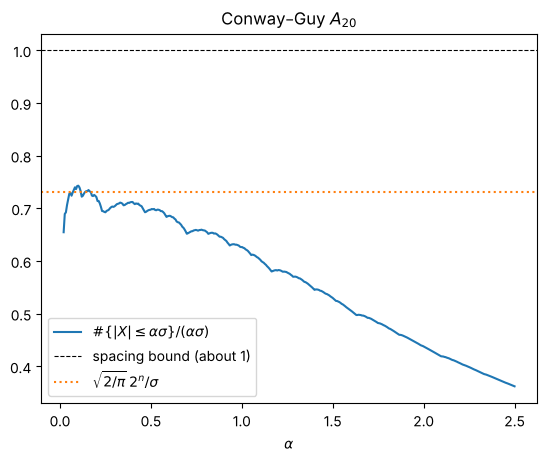

sigma / 2^n = 1.0910900856720185   sqrt(2/pi) = 0.7978845608028654


In [3]:
import matplotlib.pyplot as plt
n = 20; A = cg(n); v = signed_values(A); s = math.sqrt(sum(a * a for a in A))
alphas = np.linspace(0.02, 2.5, 400)
ratio = [2**n * (np.searchsorted(v, al * s, 'right') - np.searchsorted(v, -al * s, 'left')) / 2**n / (al * s) for al in alphas]
plt.plot(alphas, np.array(ratio) * 2**n / 2**n, label=r"$\#\{|X|\leq\alpha\sigma\}/(\alpha\sigma)$")
plt.axhline(1, color='k', ls='--', lw=.8, label="spacing bound (about 1)")
plt.axhline(math.sqrt(2 / math.pi) * 2**n / s, color='C1', ls=':', label=r"$\sqrt{2/\pi}\,2^n/\sigma$")
plt.xlabel(r"$\alpha$"); plt.legend(); plt.title(f"Conway–Guy $A_{{{n}}}$"); plt.show()
print("sigma / 2^n =", s / 2**n, "  sqrt(2/pi) =", math.sqrt(2 / math.pi))

Near $\alpha=0$ the curve sits at about $\sqrt{2/\pi}\,2^n/\sigma$ (the normal density at $0$, times $2^n/\sigma$), and it can never exceed about $1$, because the values are $2$ apart. So $\sqrt{2/\pi}\,2^n/\sigma\lesssim1$, that is $\sigma\gtrsim\sqrt{2/\pi}\,2^n$, which is the heart of the theorem. For $A_{20}$ we find $\sigma/2^n\approx1.09$, comfortably above $0.80$. The loss is in the last line of the proof, $\sigma\le\sqrt n\,a_n$: it is nearly an equality for the Conway–Guy sets, whose elements are all close to $a_n$, but it cannot be improved in general by this method, one reason why the constant $\sqrt{2/\pi}$ has not moved since 2021.

**P2.3.** A down-set is determined by its maximal elements, but the simplest enumeration for $n\le5$ grows the family set by set in order of size: a set may be added only if all its subsets of size one less are in.

In [4]:
from functools import lru_cache
def downsets(n):
    subsets = sorted(range(1 << n), key=lambda S: bin(S).count('1'))
    res = []
    def rec(i, fam):
        if i == len(subsets):
            res.append(frozenset(fam)); return
        S = subsets[i]
        rec(i + 1, fam)
        if all((S & ~(1 << j)) in fam for j in range(n) if S >> j & 1):
            fam.add(S); rec(i + 1, fam); fam.discard(S)
    rec(0, set())
    return res
def boundary(fam, n):
    return {B for B in range(1 << n) if B not in fam and any((B ^ (1 << j)) in fam for j in range(n))}
for n in range(1, 6):
    D = downsets(n)
    good = [F for F in D if 0 in F and (1 << n) - 1 not in F]
    half = [F for F in good if len(F) == 2**(n - 1)]
    m_all = min(len(boundary(F, n)) for F in good)
    sizes = [len(boundary(F, n)) for F in half]
    m = min(sizes)
    print(f"n={n}  down-sets: {len(D):5d}  min boundary (all): {m_all}  "
          f"min boundary (size 2^(n-1)): {m}  C(n,n/2) = {math.comb(n, n // 2)}  attained by {sizes.count(m)} of {len(half)}")

n=1  down-sets:     3  min boundary (all): 1  min boundary (size 2^(n-1)): 1  C(n,n/2) = 1  attained by 1 of 1
n=2  down-sets:     6  min boundary (all): 1  min boundary (size 2^(n-1)): 2  C(n,n/2) = 2  attained by 2 of 2
n=3  down-sets:    20  min boundary (all): 1  min boundary (size 2^(n-1)): 3  C(n,n/2) = 3  attained by 1 of 4
n=4  down-sets:   168  min boundary (all): 1  min boundary (size 2^(n-1)): 6  C(n,n/2) = 6  attained by 4 of 24
n=5  down-sets:  7581  min boundary (all): 1  min boundary (size 2^(n-1)): 10  C(n,n/2) = 10  attained by 1 of 621


Over all down-sets the minimum boundary is $1$ (the family of all sets except $[n]$): the shortcut is false, which is how the first draft of the chapter was caught. Among the down-sets of size $2^{n-1}$, the minimum is exactly $\binom n{\lfloor n/2\rfloor}$, as Harper's theorem predicts; for odd $n$ the Hamming ball $\{S:|S|\le\lfloor n/2\rfloor\}$ attains it (Exercise 2.3). The counts $2,3,6,20,168,7581$ are the Dedekind numbers, OEIS A000372.

**P2.4.**

In [5]:
def second_proof(a):
    n = len(a); tot = sum(a)
    val = [2 * sum(a[j] for j in range(n) if S >> j & 1) - tot for S in range(1 << n)]  # = 2 a.eta_S
    F = {S for S in range(1 << n) if val[S] < 0}
    B = boundary(F, n)
    nums = sorted(val[S] / 2 for S in B)
    ints = all(abs(x - round(x)) < 1e-9 for x in np.diff(nums)) if len(nums) > 1 else True
    return len(B), nums[0], nums[-1], len(set(nums)) == len(nums), ints
for n in range(4, 15, 2):
    a = cg(n); m, lo, hi, distinct, gaps = second_proof(a)
    print(f"n={n:2d}  |dF|={m:5d}  C(n,n/2)={math.comb(n, n//2):5d}  a_n={a[-1]:5d}  values in [{lo}, {hi}]  distinct: {distinct}, integer gaps: {gaps}")

n= 4  |dF|=    6  C(n,n/2)=    6  a_n=    7  values in [0.5, 5.5]  distinct: True, integer gaps: True
n= 6  |dF|=   20  C(n,n/2)=   20  a_n=   24  values in [0.5, 21.5]  distinct: True, integer gaps: True
n= 8  |dF|=   73  C(n,n/2)=   70  a_n=   84  values in [0.5, 83.5]  distinct: True, integer gaps: True
n=10  |dF|=  256  C(n,n/2)=  252  a_n=  309  values in [1.0, 307.0]  distinct: True, integer gaps: True
n=12  |dF|=  938  C(n,n/2)=  924  a_n= 1164  values in [0.5, 1162.5]  distinct: True, integer gaps: True
n=14  |dF|= 3457  C(n,n/2)= 3432  a_n= 4484  values in [2.5, 4480.5]  distinct: True, integer gaps: True


The numbers $a\cdot\eta_B$ are half-integers or integers (depending on the parity of $\sum a_i$), but their *differences* are integers, which is all the proof uses. The boundary is often far larger than $\binom n{\lfloor n/2\rfloor}$, and still at most $a_n$: the boundary values fill a good part of $(0,a_n)$.

**P2.5.** Represent the law of $X+\sum a_i$ (shifted to be non-negative) as a vector of length $M$; convolution becomes a product of FFTs. Each factor $\frac12(\delta_0+\delta_{2a_i})$ has Fourier transform $\frac12(1+e^{-2\pi i\,2a_ik/M})$, so we never even need to convolve step by step.

In [6]:
def law_fft(A):
    M = 2 * sum(A) + 1
    k = np.arange(M)
    spec = np.ones(M, dtype=complex)
    for a in A:
        spec *= 0.5 * (1 + np.exp(-2j * np.pi * 2 * a * k / M))
    p = np.fft.ifft(spec).real
    return np.clip(p, 0, None)            # p[v + sum A] = P(X = v)
def elkies(A):
    p = law_fft(A)
    return float((p**2).sum())
for A in ([3, 5, 6, 7], [3, 4, 5, 6], cg(12)):
    print(A[:6], "integral * 2^n =", round(elkies(A) * 2**len(A), 6))
rng = np.random.default_rng(7)
A = sorted(rng.choice(10**5, 40, replace=False) + 1)
p = law_fft(A)
print("40 random numbers: max P(X=v) * 2^40 =", round(p.max() * 2**40, 3), " dissociated:", p.max() * 2**40 < 1.5)

[3, 5, 6, 7] integral * 2^n = 1.0
[3, 4, 5, 6] integral * 2^n = 1.125


[570, 855, 1003, 1080, 1120, 1140] integral * 2^n = 1.0


40 random numbers: max P(X=v) * 2^40 = 2162333.0  dissociated: False


For a dissociated set every value has probability exactly $2^{-n}$, so $\sum P(X=v)^2=2^{-n}$ and the printed ratio is $1$; a coincidence $\epsilon\cdot a=\epsilon'\cdot a$ doubles a probability, and the sum of squares jumps. That is Elkies's identity read as an algorithm. Forty numbers below $10^5$ have $2^{40}\approx10^{12}$ subset sums but at most $4\cdot10^6$ possible values, so coincidences are forced (the pigeonhole principle, as in Chapter 1), and the FFT finds them in a fraction of a second, without ever listing $10^{12}$ sums. Floating-point FFTs are accurate here to about $10^{-15}$ relative to the largest entry; for an exact verdict use integer convolutions modulo a prime (the *number-theoretic transform*, Tome C2).